The last two chapters drew pictures of a dataset that was already in good shape. Data
Visualization I warned you that every plotting library
[drops missing values without saying so](data_viz_1.ipynb#the-data), and asked you to know how many
observations a plot left out. That warning is where this chapter begins: real data arrives with gaps, with the same record
entered twice, and with values so far from the rest that they deserve a second look.

Cleaning is the work of finding those problems, deciding what each one means, and fixing
it in a way you can defend. The deciding is the hard part. A missing value can be dropped,
filled from its own column, or filled from related rows and columns, and the right choice
depends on *why* it is missing. An extreme value can be a measurement error to correct or
a real observation to keep. Every fix changes the data you analyse afterwards, so this
chapter measures what each fix costs instead of taking it on trust.

By the end of this chapter you should be able to:

- Count missing values per column with `isna()`, and read what `describe()` and `info()` already tell you about them.
- Explain the three ways values go missing — MCAR, MAR, and MNAR — and why the mechanism decides whether dropping or filling is safe.
- Drop missing data with `dropna()` and `drop(columns=...)`, and fill it with a column mean, a group mean from `groupby()`, a regression line, or nearest neighbours, measuring each fill with RMSE.
- Find and remove duplicate records with `duplicated()` and `drop_duplicates()`, choosing `subset` and `keep` deliberately.
- Flag outliers with z-scores and the IQR rule, tell a data error from a real extreme, and choose between removing, capping, and transforming.

Complete the [practice activity](#practice-activity-find-fill-and-defend)
after the worked examples.

## Set Up Your Chapter Files {#set-up-your-chapter-files}

Download the [Data Cleaning practice kit](downloads/data-cleaning-practice.zip). Extract
`stat303-data-cleaning` inside the `chapters` folder of your `stat303-1` course folder,
open `stat303-1` in VS Code, and select the course environment. The terminal opens in
`stat303-1`, so move it into the kit with `cd chapters` and then
`cd stat303-data-cleaning` before you render the activity.

```text
stat303-1/
├── .venv/
├── assignments/
└── chapters/
    └── stat303-data-cleaning/
        ├── data_cleaning_examples.ipynb
        ├── activity10.ipynb
        ├── README.md
        └── data/
            ├── GDP_missing_data.csv
            ├── GDP_complete_data.csv
            └── College.csv
```

Run `data_cleaning_examples.ipynb` for the lesson and complete `activity10.ipynb` for your
own activity report, with `stat303-data-cleaning` as the notebook working folder. Every
file is read with a relative path such as `"data/GDP_missing_data.csv"`, so the notebooks
find their data only when that folder is the working folder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.impute import KNNImputer
from sklearn.metrics.pairwise import nan_euclidean_distances
from sklearn.preprocessing import MinMaxScaler

**Environment check:** This chapter adds two packages to the four you already have.
**scikit-learn** (imported as `sklearn`) supplies the nearest-neighbour imputation, and
**SciPy** supplies a z-score function. Install them once, in the course environment. In
the VS Code terminal, with the course environment active, run:

```bash
python -m pip install scikit-learn scipy
```

If the import cell still fails, check the selected notebook kernel first: it must be the
course environment, `stat303-1/.venv`, as in
[Project Environments, Packages, and File Paths](python_venv.ipynb#install-packages-in-the-intended-environment).
The package is called `scikit-learn` when you install it but `sklearn` when you import it.

## The data

The first half of the chapter uses country-level indicators for 155 countries: GDP per
capita, life expectancy, infant mortality, illiteracy, economic activity, and so on. It
comes in two versions:

- `GDP_missing_data.csv` has values deliberately removed.
- `GDP_complete_data.csv` has the same countries in the same order with those values
  still present.

In real work you never have the second file. Here it lets us do something you otherwise
cannot: fill in a missing value, then check the guess against the truth.

In [2]:
gdp = pd.read_csv("data/GDP_missing_data.csv")
gdp_complete = pd.read_csv("data/GDP_complete_data.csv")

print(gdp.shape)
gdp.head()

(155, 12)


,economicActivityFemale,country,lifeMale,infantMortality,gdpPerCapita,economicActivityMale,illiteracyMale,illiteracyFemale,lifeFemale,geographic_location,contraception,continent
0,7.2,Afghanistan,45.0,154.0,2474.0,87.5,NaN,85.0,46.0,Southern Asia,NaN,Asia
1,7.8,Algeria,67.5,44.0,11433.0,76.4,26.1,51.0,70.3,Northern Africa,NaN,Africa
2,41.3,Argentina,69.6,22.0,NaN,76.2,3.8,3.8,76.8,South America,NaN,South America
3,52.0,Armenia,67.2,25.0,13638.0,65.0,NaN,0.5,74.0,Western Asia,NaN,Asia
4,53.8,Australia,NaN,6.0,54891.0,NaN,1.0,1.0,81.2,Oceania,NaN,Oceania


## Find the missing values

The `NaN` entries in that preview are pandas' marker for a missing value. Before you can
decide anything about them, you need to know how many there are and where.

You have already met the first tool for this. `describe()` reports a `count` for every
numeric column, and that count is the number of **non-missing** values. Every statistic
beside it — the mean, the standard deviation, the quartiles — silently skips the gaps:

In [3]:
gdp.describe()

,economicActivityFemale,lifeMale,infantMortality,gdpPerCapita,economicActivityMale,illiteracyMale,illiteracyFemale,lifeFemale,contraception
count,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,145.000000,84.000000
mean,45.935172,65.491724,37.158621,24193.482759,76.563448,13.570028,21.448897,70.615862,51.773810
std,16.875922,9.099256,34.465699,22748.764444,7.854730,16.497954,25.497045,9.923791,31.930026
min,1.900000,36.000000,3.000000,772.000000,51.200000,0.000000,0.000000,39.100000,0.000000
25%,35.500000,62.900000,10.000000,6837.000000,72.000000,1.000000,2.300000,67.500000,17.000000
50%,47.600000,67.800000,24.000000,15184.000000,77.300000,6.600000,9.720000,73.900000,65.000000
75%,55.900000,72.400000,54.000000,35957.000000,81.600000,19.500000,30.200000,78.100000,77.000000
max,90.600000,77.400000,169.000000,122740.000000,93.000000,70.500000,90.800000,82.900000,79.000000


There are 155 rows, but most columns count 145 and `contraception` only 84. `info()` shows
the same thing as "non-null" counts, and includes the text columns too:

In [4]:
gdp.info()

<class 'pandas.DataFrame'>
RangeIndex: 155 entries, 0 to 154
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   economicActivityFemale  145 non-null    float64
 1   country                 155 non-null    str    
 2   lifeMale                145 non-null    float64
 3   infantMortality         145 non-null    float64
 4   gdpPerCapita            145 non-null    float64
 5   economicActivityMale    145 non-null    float64
 6   illiteracyMale          145 non-null    float64
 7   illiteracyFemale        145 non-null    float64
 8   lifeFemale              145 non-null    float64
 9   geographic_location     155 non-null    str    
 10  contraception           84 non-null     float64
 11  continent               155 non-null    str    
dtypes: float64(9), str(3)
memory usage: 14.7 KB


Both views make you subtract from 155 in your head. The direct way is `isna()`, which you
used in [NumPy and pandas in a Real Workflow](numpy_pandas_workflow.ipynb) to find values
that failed to convert. It returns `True` wherever a value is missing. Because `True`
counts as 1, `.sum()` gives the number of missing values per column, and `.mean()` gives
the fraction:

In [5]:
gdp.isna().sum()

economicActivityFemale    10
country                    0
lifeMale                  10
infantMortality           10
gdpPerCapita              10
economicActivityMale      10
illiteracyMale            10
illiteracyFemale          10
lifeFemale                10
geographic_location        0
contraception             71
continent                  0
dtype: int64

In [6]:
missing_percent = gdp.isna().mean() * 100
missing_percent.sort_values(ascending=False).round(1)

contraception             45.8
economicActivityFemale     6.5
lifeMale                   6.5
infantMortality            6.5
gdpPerCapita               6.5
economicActivityMale       6.5
illiteracyMale             6.5
illiteracyFemale           6.5
lifeFemale                 6.5
country                    0.0
geographic_location        0.0
continent                  0.0
dtype: float64

Two patterns stand out. Eight measurement columns are each missing 10 values, about 6%,
and `contraception` is missing 71, nearly half. The country names, regions, and continents
are complete. That difference will decide how each column is treated.

::: {.callout-note}
## `isna()` and `isnull()`

You will also see `isnull()` in other people's code. It is the same method under a second
name and returns exactly the same result. This book uses `isna()` throughout.
:::

## Why values go missing

Counting tells you *how much* is missing. Before choosing a fix, ask *why*, because the
reason decides whether a fix is safe. Statisticians sort the reasons into three
mechanisms:

| Mechanism | What it means | GDP example | Dropping or a simple fill is… |
|---|---|---|---|
| **MCAR** — missing completely at random | Missingness has nothing to do with any value, observed or not | A file was corrupted and lost random rows | Safe: what remains is still a fair sample |
| **MAR** — missing at random | Missingness depends on other columns you *can* see | Countries in one continent report less often | Biased, but other columns can correct it |
| **MNAR** — missing not at random | Missingness depends on the missing value itself | The poorest countries are the ones that do not report GDP | Biased, and the data alone cannot fix it |

The names are confusing — "missing at random" is *not* the safe one — so remember the
idea rather than the label. MCAR means the gaps are like a coin flip. MAR means the gaps
follow a pattern you can see in other columns, so a fill that uses those columns can undo
the damage. MNAR means the gaps follow the very values you are missing, and any fill will
be wrong in a predictable direction.

You cannot prove which mechanism you have from the data, but you can look for evidence.
If the countries missing GDP are concentrated in one continent, the gaps are at least not
MCAR. Keep the question in mind for every fill that follows: a method that uses related
columns can help with MAR, while nothing in this chapter rescues MNAR.

## Drop missing data

The bluntest fix is to throw away anything incomplete. You used
`dropna(subset=[...])` in the workflow chapter to drop rows missing one particular
column. Called with no arguments, `dropna()` drops every row with **any** missing value:

In [7]:
print("rows before:", len(gdp))
print("rows after dropna():", len(gdp.dropna()))

rows before: 155
rows after dropna(): 42


From 155 countries to 42: over two thirds of the data gone, including thousands of
perfectly good values that happened to share a row with one gap. The culprit is mostly a
single column. `contraception` is missing for 71 countries, so almost every row has *some*
gap. A column missing half its values is a weak basis for filling anything, so the better
move is to drop that column and keep the rows:

In [8]:
gdp = gdp.drop(columns="contraception")

print("columns left:", gdp.shape[1])
print("rows after dropna():", len(gdp.dropna()))

columns left: 11
rows after dropna(): 88


Dropping one column brings `dropna()` back to 88 rows. Note that `drop(columns=...)`
returns a new DataFrame, so the result is assigned back to `gdp`; nothing changes in place.

`dropna()` has three arguments that make it less blunt:

| Argument | Effect | Here |
|---|---|---|
| `subset=["gdpPerCapita"]` | Only look for gaps in these columns | Keeps the 145 rows that have GDP |
| `how="all"` | Drop a row only if *every* value is missing | Drops nothing; no row is entirely empty |
| `thresh=10` | Keep a row only if it has at least 10 non-missing values | Keeps 143 of 155 rows |

Even 88 rows means discarding 67 countries over a handful of gaps each. Filling the gaps
instead keeps those countries, which is what the rest of this section is about.

## Fill missing values

Filling a missing value is called **imputation**, and every imputation is a guess. The
question is how good the guess is, and here, unusually, we can measure it. For the 10
countries missing GDP per capita, `gdp_complete` holds the true values, so any fill can be
scored against them.

The score is the **root mean squared error (RMSE)**: square each error, average the
squares, take the square root. It is in the same units as the data — dollars of GDP per
capita here — and smaller is better. The function below computes it for a filled GDP
column and draws each guess against the truth, so every method in this section gets the
same report:

In [9]:
gdp_missing = gdp["gdpPerCapita"].isna()       # the 10 rows we will be guessing
true_gdp = gdp_complete.loc[gdp_missing, "gdpPerCapita"]

def score_fill(filled_gdp, method):
    """Plot filled GDP against the truth for the missing rows, and return the RMSE."""
    guesses = filled_gdp[gdp_missing]
    rmse = np.sqrt(((guesses - true_gdp) ** 2).mean())

    fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
    ax.scatter(true_gdp, guesses, s=50)
    ax.axline((0, 0), slope=1, color="gray", linestyle="--", label="perfect guess")
    ax.xaxis.set_major_formatter("${x:,.0f}")
    ax.yaxis.set_major_formatter("${x:,.0f}")
    top = max(true_gdp.max(), guesses.max()) * 1.05     # same range on both axes
    ax.set(xlim=(0, top), ylim=(0, top),
           xlabel="True GDP per capita", ylabel="Filled GDP per capita",
           title=f"{method}: RMSE ${rmse:,.0f}")
    ax.legend(loc="upper left")
    plt.show()
    return rmse

`gdp_missing` is a Boolean mask, so `filled_gdp[gdp_missing]` keeps only the guessed rows.
`ax.axline((0, 0), slope=1)` draws the line where a guess equals the truth: points on it
are perfect, and the farther a point sits from it, the worse that guess. Both axes share
one range so that line is a true diagonal, and the tick formatter is the one from
[Data Visualization II](data_viz_2.ipynb).

### Fill with the column mean

The simplest guess for a missing number is the typical value of its column.
`fillna(value)` replaces every `NaN` in a Series with `value`:

mean GDP per capita: $24,193


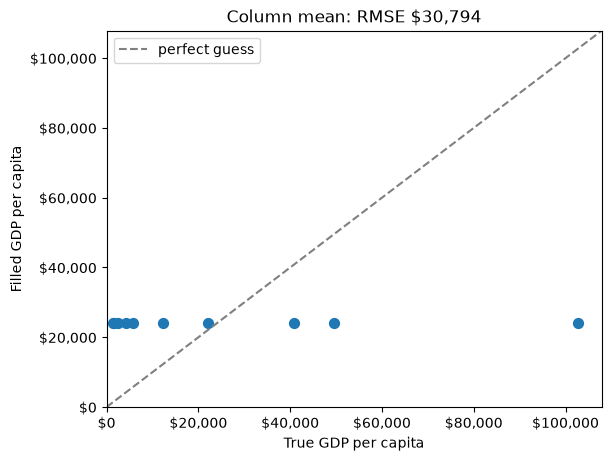

In [10]:
mean_gdp = gdp["gdpPerCapita"].mean()
print(f"mean GDP per capita: ${mean_gdp:,.0f}")

rmse_mean = score_fill(gdp["gdpPerCapita"].fillna(mean_gdp), "Column mean")

Every missing country gets the same $24,193, so the points form a horizontal line. A rich
country and a poor one receive the same guess, which is why the RMSE is about $30,800.

Filling with the median instead — `fillna(gdp["gdpPerCapita"].median())` — is the usual
advice for skewed data like GDP, and it does give a more typical value ($15,184). It
scores slightly *worse* here, about $32,100, because these particular missing countries
are not typical. Neither statistic can tell one country from another.

A column-wide fill also shrinks the column's spread, since every gap becomes the same
middle value. For a categorical column, the equivalent guess is the most common category,
`df["col"].mode()[0]`.

### Fill with a group mean

GDP per capita varies enormously by continent, which a box plot shows at once:

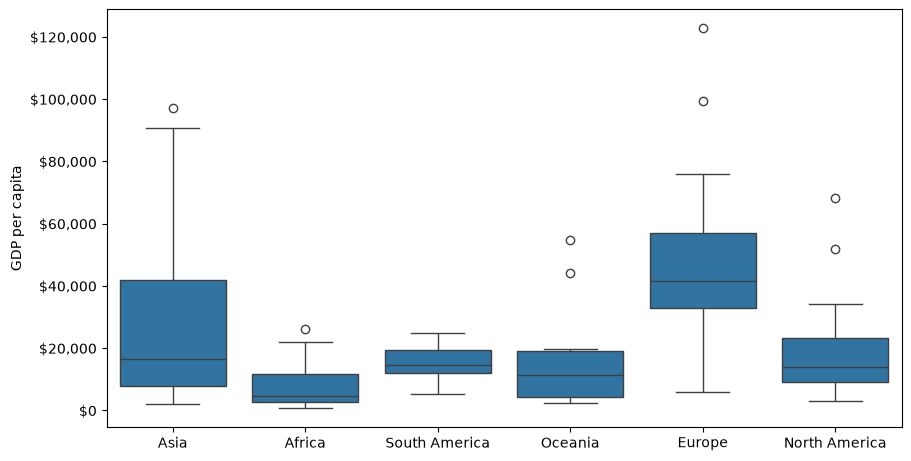

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
sns.boxplot(data=gdp, x="continent", y="gdpPerCapita", ax=ax)
ax.yaxis.set_major_formatter("${x:,.0f}")
ax.set(xlabel="", ylabel="GDP per capita")
plt.show()

A missing European country is much more likely to be near Europe's typical GDP than near
the world's. Filling each gap with **its own continent's mean** uses the `continent`
column to make a better guess, which is exactly the kind of fill that can correct MAR
missingness.

That needs a mean for each continent, and the tool for "split the rows into groups, then
compute something per group" is `groupby()`. The full story waits for
[Data Grouping and Aggregation](Data%20aggregation.ipynb); here you need only its simplest
form. `gdp.groupby("continent")["gdpPerCapita"].mean()` splits the rows by continent and
returns one mean per continent, skipping missing values as every pandas statistic does:

In [12]:
gdp.groupby("continent")["gdpPerCapita"].mean().round(0)

continent
Africa            7638.0
Asia             25923.0
Europe           45455.0
North America    19625.0
Oceania          15386.0
South America    15361.0
Name: gdpPerCapita, dtype: float64

That is one number per continent, six in all. To fill a column you need one number per
**row**: each country's own continent mean, lined up with the country. Replacing `.mean()`
with `.transform("mean")` does exactly that. It computes the same group means, then hands
each row the mean of its group, so the result has 155 values in the original row order:

0    25922.750000
1     7638.178571
2    15360.909091
3    25922.750000
4    15385.857143
Name: gdpPerCapita, dtype: float64


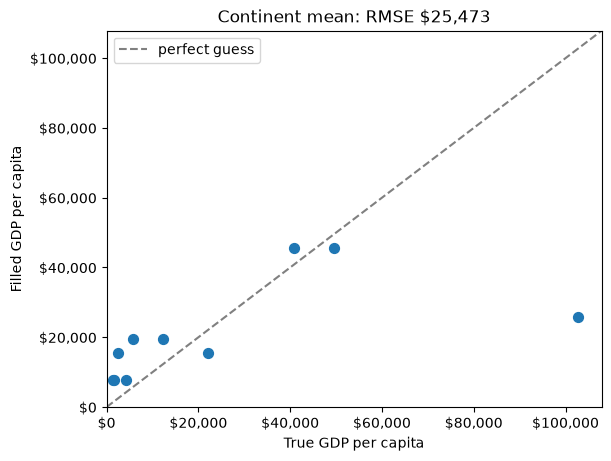

In [13]:
continent_mean = gdp.groupby("continent")["gdpPerCapita"].transform("mean")
print(continent_mean.head())

rmse_group = score_fill(gdp["gdpPerCapita"].fillna(continent_mean), "Continent mean")

`fillna()` accepts a Series as well as a single value. It fills each gap from the entry
at the same row label, so each country gets its continent's mean. The guesses now differ
by continent and the RMSE drops to about $25,500.

### Fill from a related column

A different way to use other columns is to predict the missing value from one that is
strongly related to it. `corrwith()` correlates every numeric column with GDP per capita:

In [14]:
gdp.select_dtypes("number").corrwith(gdp["gdpPerCapita"]).round(2)

economicActivityFemale    0.08
lifeMale                  0.58
infantMortality          -0.57
gdpPerCapita              1.00
economicActivityMale     -0.13
illiteracyMale           -0.48
illiteracyFemale         -0.45
lifeFemale                0.62
dtype: float64

Female life expectancy has the strongest correlation, 0.62. The idea is to fit a straight
line predicting GDP from `lifeFemale` — the same least-squares line seaborn's `regplot`
drew in [Data Visualization I](data_viz_1.ipynb) — and read each missing country's GDP
off that line.

[`np.polyfit(x, y, 1)`](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html)
fits that line and returns its slope and intercept; the `1` asks for a straight line. It
cannot handle `NaN`, so it is fitted only on the countries that have both values:

GDP per capita ≈ -79,453 + 1,473 × lifeFemale


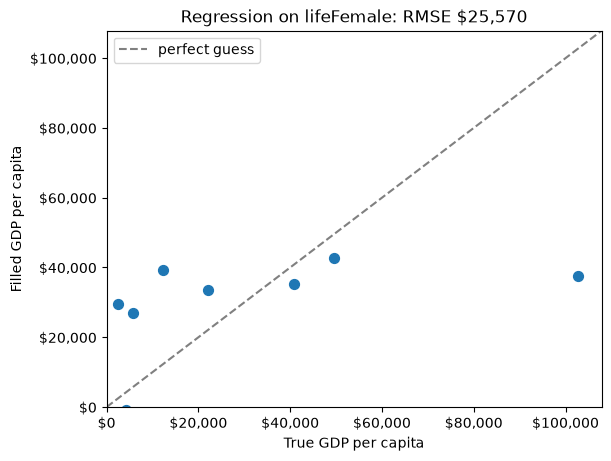

In [15]:
both_known = gdp["lifeFemale"].notna() & gdp["gdpPerCapita"].notna()
slope, intercept = np.polyfit(gdp.loc[both_known, "lifeFemale"],
                              gdp.loc[both_known, "gdpPerCapita"], 1)
print(f"GDP per capita ≈ {intercept:,.0f} + {slope:,.0f} × lifeFemale")

predicted_gdp = intercept + slope * gdp["lifeFemale"]
rmse_regression = score_fill(gdp["gdpPerCapita"].fillna(predicted_gdp), "Regression on lifeFemale")

Each extra year of female life expectancy predicts about $1,473 more GDP per capita. The
RMSE, about $25,600, is close to the continent mean's: one strongly related column carries
roughly as much information as the continent does. This works only because `lifeFemale`
is present for every country missing GDP; a predictor with its own gaps would leave those
rows unfilled.

### Fill from the nearest neighbours

The last two fills each used one other column. **K-nearest-neighbour (KNN) imputation**
uses all of them at once: to fill a gap in one country, find the K countries most similar
to it across every other numeric column, and average their values.

"Most similar" means smallest **Euclidean distance**, the straight-line distance you
learned in geometry, computed across all the columns a pair of rows both have. A toy
array of four rows and three columns shows the mechanics:

In [16]:
toy = np.array([[1, 2, np.nan],
                [3, 4, 3],
                [np.nan, 6, 5],
                [8, 8, 7]])

nan_euclidean_distances(toy)

array([[ 0.        ,  3.46410162,  6.92820323, 11.29158979],
       [ 3.46410162,  0.        ,  3.46410162,  7.54983444],
       [ 6.92820323,  3.46410162,  0.        ,  3.46410162],
       [11.29158979,  7.54983444,  3.46410162,  0.        ]])

Entry $(i, j)$ is the distance from row $i$ to row $j$, counting rows from 0 as NumPy
does. `nan_euclidean_distances` from scikit-learn skips any coordinate where either row is
missing and scales the result up to make up for it. Row 0 is closest to row 1 (3.46),
then row 2 (6.93). Row 2 is equally close to rows 1 and 3 (3.46 each).

`KNNImputer` does the averaging. Like every scikit-learn tool, it is used in two steps:
create the object with its settings, then call `fit_transform()` on the data:

In [17]:
imputer = KNNImputer(n_neighbors=2)
imputer.fit_transform(toy)

array([[1. , 2. , 4. ],
       [3. , 4. , 3. ],
       [5.5, 6. , 5. ],
       [8. , 8. , 7. ]])

With `n_neighbors=2`, each gap is the mean of the two nearest rows that have a value in
that column. Row 0's missing third value is 4.0, the mean of rows 1 and 2 (3 and 5).
Row 2's missing first value is 5.5, the mean of rows 1 and 3 (3 and 8).

On the real data, one more step matters. Distance adds up differences across columns, and
GDP per capita runs into the tens of thousands while life expectancy runs from about 40 to
80. Unscaled, GDP alone would decide who counts as a neighbour. `MinMaxScaler` rescales
each column to run from 0 to 1, so every column gets an equal say; it remembers each
column's original range, so `inverse_transform()` can convert back to dollars afterwards:

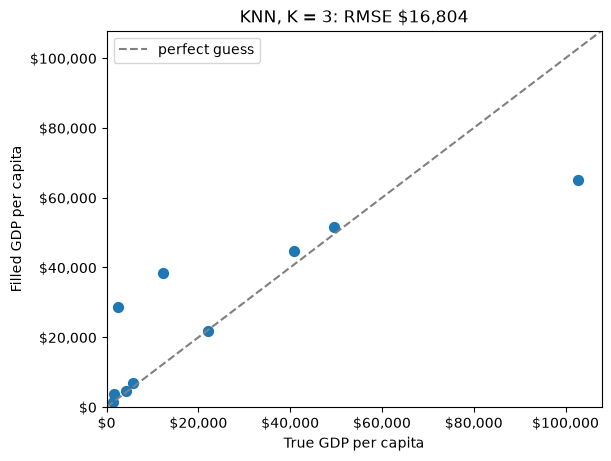

In [18]:
numeric = gdp.select_dtypes("number")          # the eight measurement columns

scaler = MinMaxScaler()
scaled = scaler.fit_transform(numeric)         # every column now runs from 0 to 1

imputer = KNNImputer(n_neighbors=3)
filled_scaled = imputer.fit_transform(scaled)  # gaps filled from 3 nearest countries

filled = pd.DataFrame(scaler.inverse_transform(filled_scaled),
                      columns=numeric.columns, index=numeric.index)

rmse_knn = score_fill(filled["gdpPerCapita"], "KNN, K = 3")

Both scikit-learn steps return plain NumPy arrays, so the last step wraps the result back
into a DataFrame with the original column names and row labels. The RMSE falls to about
$16,800, the best so far, because KNN finds countries that resemble the missing one on
every measurement at once. It also fills the gaps in the other seven columns in the same
pass.

The choice $K = 3$ matters more than it looks. On this data, $K = 2$ gives about $21,400
and $K = 5$ about $23,500, so K is a setting to choose carefully rather than a detail.
Choosing it properly uses a technique called cross-validation, which comes in the next
course of the sequence.

### Forward fill, and when not to use it

`ffill()` fills each gap with the value in the row **above** it (`bfill()` uses the row
below). For data in a meaningful order, such as daily temperatures, yesterday's value is
a sensible guess for a missing today. Our countries are in alphabetical order, which has
nothing to do with GDP:

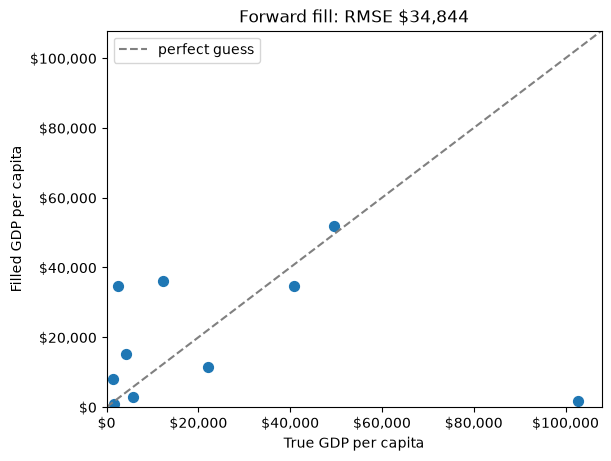

In [19]:
rmse_ffill = score_fill(gdp["gdpPerCapita"].ffill(), "Forward fill")

Forward fill gives the worst result of all, about $34,800: worse than guessing the mean,
because the neighbour in alphabetical order is no guide to a country's wealth. It also
cannot fill a gap in the very first row, since there is nothing above it; Afghanistan's
missing `illiteracyMale` survives a forward fill of the whole table.

### Compare the fills

In [20]:
pd.Series({
    "Forward fill": rmse_ffill,
    "Column mean": rmse_mean,
    "Regression on lifeFemale": rmse_regression,
    "Continent mean": rmse_group,
    "KNN, K = 3": rmse_knn,
}).round(0).rename("RMSE")

Forward fill                34844.0
Column mean                 30794.0
Regression on lifeFemale    25570.0
Continent mean              25473.0
KNN, K = 3                  16804.0
Name: RMSE, dtype: float64

The ranking follows how much information each method uses. Forward fill uses an
irrelevant ordering, the column mean uses only the column itself, the next two each add
one related variable, and KNN uses every column at once. That is the general lesson, but
the exact order is specific to this data. On another dataset a group mean can beat KNN,
which is why the comparison is worth running whenever you can.

Every fill shares one limit: it invents values that look like real data. Whatever you
choose, record which values were filled and how, so a reader can judge how much the
results depend on your guesses.

## Find and remove duplicates

A **duplicate** is the same record appearing more than once. Duplicates come from data
entry errors, from combining files that overlap, or from a system that saved a record
twice, and they are dangerous because they look like real data: a duplicated student is
counted twice in every total and average.

A small table of student records, with some entered twice, shows the tools:

In [21]:
students = pd.DataFrame({
    "student_id": [101, 102, 103, 101, 104, 102, 105, 103],
    "name": ["Alice", "Bob", "Charlie", "Alice", "David", "Bob", "Eve", "Charlie"],
    "major": ["CS", "Math", "CS", "CS", "Physics", "Math", "Biology", "Stats"],
    "gpa": [3.8, 3.5, 3.9, 3.8, 3.7, 3.5, 3.6, 3.9],
})
students

,student_id,name,major,gpa
0,101,Alice,CS,3.8
1,102,Bob,Math,3.5
2,103,Charlie,CS,3.9
3,101,Alice,CS,3.8
4,104,David,Physics,3.7
5,102,Bob,Math,3.5
6,105,Eve,Biology,3.6
7,103,Charlie,Stats,3.9


`duplicated()` returns a Boolean Series that is `True` for every row identical to an
earlier one. Summing it counts the repeats, and using it as a mask shows them:

In [22]:
print("exact duplicate rows:", students.duplicated().sum())
students[students.duplicated()]

exact duplicate rows: 2


,student_id,name,major,gpa
3,101,Alice,CS,3.8
5,102,Bob,Math,3.5


Only the second copy of each record is flagged: by default the **first** occurrence counts
as the original. To see every copy, including the first, pass `keep=False`:

In [23]:
students[students.duplicated(keep=False)]

,student_id,name,major,gpa
0,101,Alice,CS,3.8
1,102,Bob,Math,3.5
3,101,Alice,CS,3.8
5,102,Bob,Math,3.5


Rows 0 and 3 (Alice) and rows 1 and 5 (Bob) are identical in every column. Charlie is
not flagged, because his two rows differ in `major`. Whether those are two records of
one student or a data error is a question about the data, not about pandas. If
`student_id` is supposed to be unique, check that column alone with `subset`:

In [24]:
print("repeated student IDs:", students.duplicated(subset=["student_id"]).sum())
students[students.duplicated(subset=["student_id"], keep=False)]

repeated student IDs: 3


,student_id,name,major,gpa
0,101,Alice,CS,3.8
1,102,Bob,Math,3.5
2,103,Charlie,CS,3.9
3,101,Alice,CS,3.8
5,102,Bob,Math,3.5
7,103,Charlie,Stats,3.9


By ID there are three repeats, and Charlie's conflicting rows now appear. Exact
duplicates are safe to remove; conflicting ones need a decision about which version is
right.

`drop_duplicates()` removes duplicates and takes the same `subset` and `keep` arguments:
`keep="first"` (the default) keeps the first copy, `keep="last"` keeps the last, and
`keep=False` removes every copy.

In [25]:
deduplicated = students.drop_duplicates()
print(len(students), "rows ->", len(deduplicated), "rows")
deduplicated

8 rows -> 6 rows


,student_id,name,major,gpa
0,101,Alice,CS,3.8
1,102,Bob,Math,3.5
2,103,Charlie,CS,3.9
4,104,David,Physics,3.7
6,105,Eve,Biology,3.6
7,103,Charlie,Stats,3.9


Removing exact duplicates leaves six rows, including both of Charlie's. Had you dropped by
ID instead — `students.drop_duplicates(subset=["student_id"], keep="last")` — you would
have kept one Charlie, the `Stats` row, which is the right choice only if you know the
later entry is the correction. `keep` encodes that judgement, so choose it on purpose.

The GDP data has no repeats, either as whole rows or as countries:

In [26]:
print("duplicate rows:", gdp.duplicated().sum())
print("repeated countries:", gdp["country"].duplicated().sum())

duplicate rows: 0
repeated countries: 0


## Find and handle outliers

An **outlier** is an observation far from the rest of the data. Outliers matter because
the mean, the standard deviation, and a fitted line are all pulled toward them, so a few
extreme values can change the story a summary tells.

This section uses data on 777 US colleges from *An Introduction to Statistical Learning*.
The first column holds the college names, so `index_col=0` uses it as the row labels, as
in [Reading Data](Reading_data.ipynb):

In [27]:
college = pd.read_csv("data/College.csv", index_col=0)
print(college.shape)
college[["Private", "Apps", "Enroll", "Expend", "Grad.Rate"]].head()

(777, 18)


,Private,Apps,Enroll,Expend,Grad.Rate
Abilene Christian University,Yes,1660,721,7041,60
Adelphi University,Yes,2186,512,10527,56
Adrian College,Yes,1428,336,8735,54
Agnes Scott College,Yes,417,137,19016,59
Alaska Pacific University,Yes,193,55,10922,15


`Expend` is instructional expenditure per student, in dollars, and `Grad.Rate` is the
graduation rate as a percentage.

### See them

A box plot marks outliers directly: the points beyond the whiskers. A histogram shows
the same values as a long, thin tail:

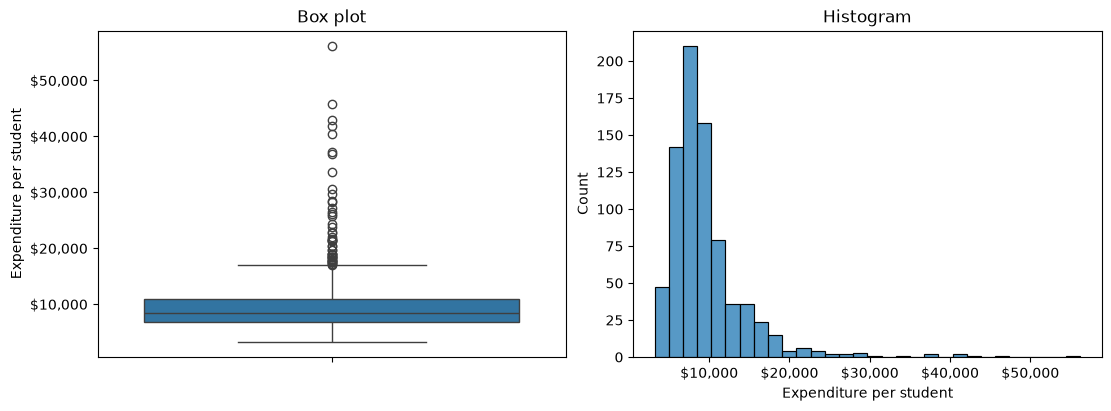

In [28]:
fig, (ax_box, ax_hist) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")

sns.boxplot(data=college, y="Expend", ax=ax_box)
ax_box.yaxis.set_major_formatter("${x:,.0f}")
ax_box.set(ylabel="Expenditure per student", title="Box plot")

sns.histplot(data=college, x="Expend", bins=30, ax=ax_hist)
ax_hist.xaxis.set_major_formatter("${x:,.0f}")
ax_hist.set(xlabel="Expenditure per student", title="Histogram")

plt.show()

Most colleges spend between about $5,000 and $15,000 per student, and a tail of
colleges spends far more, up to Johns Hopkins at $56,233. A picture tells you outliers
exist; to work with them you need a rule that flags each one.

### Flag them with a rule

**The z-score rule.** A z-score measures how many standard deviations a value is from the
mean, $z = (x - \bar{x}) / s$. A common convention flags values with $|z| > 3$.
`stats.zscore()` from SciPy computes z-scores for a whole column:

In [29]:
z = stats.zscore(college["Expend"])
z_outlier = np.abs(z) > 3
print("z-score outliers:", z_outlier.sum())

z-score outliers: 16


`stats.zscore()` returns a NumPy array, so `np.abs()` takes the absolute value and the
comparison gives a Boolean array you can sum. It divides by the standard deviation with
`ddof=0`, the NumPy default from [NumPy Fundamentals](numpy_fundamentals.ipynb);
computing `(x - x.mean()) / x.std(ddof=0)` by hand gives the same values.

**The IQR rule.** This is the rule the box plot used. With $Q1$ and $Q3$ the 25th and 75th
percentiles and $IQR = Q3 - Q1$, anything below $Q1 - 1.5 \times IQR$ or above
$Q3 + 1.5 \times IQR$ is an outlier. These boundaries are called **Tukey's fences**.
`quantile()` gives the percentiles:

In [30]:
q1, q3 = college["Expend"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"fences: ${lower:,.0f} to ${upper:,.0f}")

iqr_outlier = (college["Expend"] < lower) | (college["Expend"] > upper)
print("IQR outliers:", iqr_outlier.sum())

fences: $632 to $16,948
IQR outliers: 48


The IQR rule flags 48 colleges and the z-score rule only 16. The difference comes from
the right skew. The z-score uses the mean and standard deviation, and the long tail
inflates both, so a value has to be very extreme to reach $|z| > 3$. The quartiles barely
move with the tail, so the IQR fences stay close to the bulk of the data.

| Rule | Built on | Assumes | Flags |
|---|---|---|---|
| z-score | Mean and standard deviation | Roughly bell-shaped data | Fewer, more extreme values |
| IQR | Quartiles | Nothing about shape | More values; suits skewed data |

Neither number is the "true" count of outliers. A rule only nominates candidates; deciding
what to do with them comes next.

### Ask whether it is an error

Before handling an outlier, ask whether the value is **possible**. The graduation rates
show the difference:

In [31]:
college["Grad.Rate"].describe()

count    777.00000
mean      65.46332
std       17.17771
min       10.00000
25%       53.00000
50%       65.00000
75%       78.00000
max      118.00000
Name: Grad.Rate, dtype: float64

In [32]:
college.loc[college["Grad.Rate"] > 100, ["Grad.Rate"]]

,Grad.Rate
Cazenovia College,118


A graduation rate of 118% is impossible, so Cazenovia College's value is a **data
error**, not an extreme. Capping it at some fence would still leave an invented number.
The honest fix is to mark it as missing, which turns it into the problem the first half
of this chapter solved:

```python
college.loc[college["Grad.Rate"] > 100, "Grad.Rate"] = np.nan
```

Johns Hopkins spending $56,233 per student is the opposite case: extreme, but entirely
plausible for a research university. Removing it would delete a real fact about American
colleges. Errors get corrected or set to missing; real extremes get a deliberate choice
from the methods below.

### Handle them

Four common ways to handle real outliers, each applied to `Expend` with the IQR fences:

In [33]:
expend = college["Expend"]

removed = expend[~iqr_outlier]                         # drop flagged colleges
capped = expend.clip(lower, upper)                     # pull them back to the fences
median_filled = expend.mask(iqr_outlier, removed.median())   # replace with a typical value
logged = np.log(expend)                                # compress the whole scale

pd.DataFrame({
    "rows": [len(expend), len(removed), len(capped), len(median_filled)],
    "mean": [expend.mean(), removed.mean(), capped.mean(), median_filled.mean()],
    "std": [expend.std(), removed.std(), capped.std(), median_filled.std()],
}, index=["original", "removed", "capped", "median-filled"]).round(0)

,rows,mean,std
original,777,9660.0,5222.0
removed,729,8671.0,2839.0
capped,777,9183.0,3396.0
median-filled,777,8638.0,2753.0


`clip(lower, upper)`, from [Pandas Intermediate](pandas_intermediate.ipynb), moves any
value outside the range to the nearest fence; this is also called **winsorizing**.
`mask(condition, value)` replaces the values where the condition is `True`.

All three shrink the standard deviation from about $5,200 to under $3,400, and all three
lower the mean. That is the point of handling outliers, and also the danger: the cleaned
column describes colleges that spend less, and vary less, than the real ones do.

| Method | Keeps every row | Cost |
|---|---|---|
| Remove | No | Loses the colleges, and anything else they recorded |
| Cap (winsorize) | Yes | Invents a boundary value; real extremes look ordinary |
| Replace with the median | Yes | Invents a typical value; spread shrinks most |
| Log transform | Yes | Changes the units, so results must be read on a log scale |

The log transform is different in kind. It keeps every value and its order, but
compresses large values more than small ones, so the skewness of `Expend` drops from
about 3.5 to 0.8. It suits strictly positive, right-skewed quantities such as money, and
`np.log1p()` handles columns that contain zeros.

Whichever you choose, report it: how many values were flagged, by which rule, and what
was done to them.

## Summary Cheat Sheet {#summary-cheat-sheet}

**Find missing values.**

| Goal | Code |
|---|---|
| Count per column | `df.isna().sum()` |
| Percent per column | `df.isna().mean() * 100` |
| Non-missing counts | `df.describe()` (`count` row), `df.info()` |

**Drop or fill.**

| Goal | Code |
|---|---|
| Drop rows with any gap | `df.dropna()` |
| Only check some columns | `df.dropna(subset=["col"])` |
| Keep rows with at least n values | `df.dropna(thresh=n)` |
| Drop a mostly empty column | `df.drop(columns="col")` |
| Fill with one value | `df["col"].fillna(df["col"].mean())` |
| Fill with each row's group mean | `df["col"].fillna(df.groupby("g")["col"].transform("mean"))` |
| Fill from a related column | `slope, intercept = np.polyfit(x, y, 1)` on complete rows |
| Fill from nearest neighbours | `MinMaxScaler`, then `KNNImputer(n_neighbors=k).fit_transform(...)` |
| Fill from the row above | `df.ffill()` — only for ordered data |
| Score a fill against the truth | `np.sqrt(((guess - truth) ** 2).mean())` |

**Duplicates.**

| Goal | Code |
|---|---|
| Count repeated rows | `df.duplicated().sum()` |
| Show every copy | `df[df.duplicated(keep=False)]` |
| Check one key column | `df.duplicated(subset=["id"])` |
| Remove repeats | `df.drop_duplicates(subset=..., keep="first" / "last" / False)` |

**Outliers.**

| Goal | Code |
|---|---|
| z-scores | `z = stats.zscore(s)`; flag `np.abs(z) > 3` |
| IQR fences | `q1, q3 = s.quantile([0.25, 0.75])`; `q1 - 1.5 * iqr`, `q3 + 1.5 * iqr` |
| Impossible value → missing | `df.loc[condition, "col"] = np.nan` |
| Cap at the fences | `s.clip(lower, upper)` |
| Replace flagged values | `s.mask(flags, value)` |
| Compress a right skew | `np.log(s)` or `np.log1p(s)` |

The rule to remember: **measure what a fix costs before you trust it.**

## Practice Activity: Find, Fill, and Defend {#practice-activity-find-fill-and-defend}

**Goal:** Find each kind of problem in real data, choose a fix, and measure or justify what the fix did.

**File:** `activity10.ipynb` from the [practice kit](downloads/data-cleaning-practice.zip).

**Submit:** `activity10.html` through the final upload question in the Data Cleaning Canvas quiz.

**This section contains the complete activity instructions.** The starter loads the data and supplies spaces to record your work. Open `activity10.ipynb` from the folder prepared in [Set Up Your Chapter Files](#set-up-your-chapter-files), using the same project environment. The worked examples above are preparation, not additional submission requirements.

The starter loads `gdp` and `gdp_complete` from the kit's `data/` folder, `college` with the college names as row labels, and a small `enrollments` table with repeated records.

### A. Count the Gaps, and the Cost of Dropping Them {.unnumbered}

- Replace `Your Name` in the opening Raw cell's `author` field. Run the setup cell; it must report the shapes `(155, 12)`, `(155, 13)`, `(777, 18)`, and `(9, 4)`.
- Report the number and the percentage of missing values in each column of `gdp`, and name the column you would drop and why.
- Report how many rows `dropna()` keeps before and after dropping that column, and say in one sentence why dropping rows is a poor fix here.

### B. Fill One Column Two Ways, and Score Both {.unnumbered}

- Fill the missing values of `lifeFemale` in `gdp` with the column mean, and again with each country's continent mean using `groupby("continent")` and `transform("mean")`.
- Using `gdp_complete`, compute the RMSE of each fill on the rows where `lifeFemale` was missing.
- Say which fill did better and give a reason based on what each one uses.

### C. Duplicates, Exact and by Key {.unnumbered}

- Count the exact duplicate rows in `enrollments`, then count repeated values of `student_id` alone, and show every copy of each.
- Remove the duplicates so that each student appears once, and state which `keep` value you chose and why it fits the rows you saw.

### D. Outlier or Error {.unnumbered}

- Flag outliers in `college["Grad.Rate"]` with the IQR rule and with the z-score rule, and report how many each flags.
- Show the flagged colleges. Identify the value that is impossible rather than extreme, and set it to missing.
- For one flagged value that is possible, say whether you would keep, cap, or remove it, and justify the choice in one or two sentences.

### Render and Submit {.unnumbered}

Restart the kernel, run all cells in order, resolve unexpected errors, and save. Include your outputs and explanations for A–D, and a short Markdown completion note. From `stat303-data-cleaning` in the terminal, run:

```text
quarto render activity10.ipynb --to html
```

Follow the [Quarto refresher](vscode_setup.ipynb#render-and-submit-with-quarto): inspect the HTML and a copy opened outside the project folder, and confirm that every output appears and your name is on the report. Upload only `activity10.html` to the Data Cleaning Canvas quiz; keep your notebook locally.

**HTML grading (16 points):** missing counts and percentages, the dropped column, and the `dropna()` comparison (4); both fills of `lifeFemale`, both RMSEs, and the explanation (4); exact and key-based duplicates found, removed, and the `keep` choice justified (4); both outlier rules, the impossible value set to missing, and one justified decision (3); name, readable report, and completion note (1).

## Extended Practice {#extended-practice}

These longer exercises are additional practice, not requirements for the Canvas quiz.
Work in a separate notebook beside your activity and load the data the way the chapter
does. Include your code, outputs, and explanations.

### Every Fill for One Column

Score all five fills from the chapter — forward fill, column mean, continent mean,
regression on the most correlated column, and KNN — for `infantMortality` instead of GDP
per capita. Does the ranking match the one for GDP? Then try KNN with K from 1 to 10 and
plot RMSE against K. What does the plot say about choosing K by trying one value?

### What a Fill Does to a Distribution

Fill `gdpPerCapita` with the column mean and with KNN, and draw the three distributions —
the original non-missing values and the two filled columns — as histograms on one figure
with shared axes. Which fill changes the shape of the distribution, and why does that
matter for a summary like the standard deviation?

### Handling Outliers in Expenditure

Apply all four outlier treatments to `college["Expend"]` and draw a scatter plot of
`Grad.Rate` against each version, with a `regplot` line. How does the slope of the line
change? Which treatment would you report, and what would you say about it in a caption?

### A Cleaning Log

Clean `GDP_missing_data.csv` from start to finish: drop what should be dropped, fill what
should be filled, and check for duplicates and outliers in every numeric column. Keep a
log as a small DataFrame with one row per step — what was found, what you did, and how
many values it affected — and argue, for one column, which missingness mechanism seems
most plausible and what evidence in the data supports it.

## Before You Move On {#before-you-move-on}

The habit to carry forward is measuring a fix before you trust it. Dropping rows, filling
gaps, removing repeats, and capping extremes each change the data every later step will
see, and each one can be checked: how many rows it removed, how far its guesses were from
the truth, how much it moved a mean or a standard deviation.

The other habit is asking what a problem means before choosing a fix. A gap may follow a
pattern you can see in other columns, or one you cannot. A repeated record may be a copy
or a correction. An extreme value may be an error or a fact. The code for every fix in
this chapter is a line or two; the judgement around it is the work.

For any dataset you clean, you should be able to answer five questions:

1. How many values were missing in each column, and why might they be missing?
2. What did you drop, and how much data did that cost?
3. How did you fill the rest, and how good were those guesses?
4. Were any records duplicated, and how did you decide which copy to keep?
5. Which values did you flag as outliers, and which of them were errors?

Continue to [Data Preparation](Data_preparation.ipynb), where clean data is reshaped into
the form an analysis needs.

References: [pandas: working with missing data](https://pandas.pydata.org/docs/user_guide/missing_data.html),
[`DataFrame.dropna`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.dropna.html),
[`Series.fillna`](https://pandas.pydata.org/docs/reference/api/pandas.Series.fillna.html),
[`DataFrame.groupby`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html),
[`DataFrame.duplicated`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.duplicated.html),
[`DataFrame.drop_duplicates`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop_duplicates.html),
[`np.polyfit`](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html),
[scikit-learn `KNNImputer`](https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html),
[`MinMaxScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html),
and [SciPy `stats.zscore`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.zscore.html).